## 09.3 Coding Parallel Algorithms

```
date: "Block 09"
author: "Daniel Lawson"
email: dan.lawson@bristol.ac.uk
output: html_document
version: 5.0.0
```

## Portfolio 09.3.1 - Big Compute vs Big Data

* You are working on a problem for which there is a (potentially expensive) **simulator** and a (potentially inexpensive) **emulator**, which can estimate what the simulator will output, and can be updated from the simulator. You can run several simulator parameters (say 64) in parallel.
    - What choices impact how you might use the emulator to choose good parameter choices?
    - An example is given for a Random Forest. The Forest is our simulator that we are trying to model, and the regression is an emulator for its performance.

# 0. Introduction

This workshop answers a practical question: **my laptop has 8 (or 16) cores and I have a pile of jobs. How do I run them all at once?**

It puts into practice ideas from the lecture, notably:

* **Embarrassingly parallel** computation as a parallel **map**, followed by a **reduce**,
* Doing this safely from a notebook, using **joblib**,
* **Asynchronous** computation and **futures**, using the standard library,
* **Overheads** and **speedup**, and why 16 cores rarely gives a 16x speedup,
* A real example: a parallel **hyperparameter search** for a random forest, examining how each hyperparameter trades accuracy against compute, and building an **emulator** to choose the best trade-off.

## 0.1 Prerequisites:

In [1]:
## Install requirements, e.g.:
# !pip install numpy pandas matplotlib scikit-learn joblib

In [2]:
## Might need this first:
# !pip install pipreqsnb
!pipreqsnb --savepath requirements-block09.3.txt block09.3-Multiprocessing.ipynb

pipreqs  --savepath requirements-block09.3.txt /Users/madjl/teach/dst-private/Workshops/__temp_pipreqsnb_folder
INFO: Not scanning for jupyter notebooks.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
INFO: Successfully saved requirements file in requirements-block09.3.txt


In [3]:
print("\nREQUIREMENTS:\n")
with open('requirements-block09.3.txt', 'r') as f:
    print(f.read())


REQUIREMENTS:

joblib==1.5.2
matplotlib==3.11.2
numpy==2.5.4
pandas==3.0.6
scikit_learn==1.9.1
scipy==1.18.1



In [4]:
import os
import time
from functools import reduce
from operator import add

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed

# 1. Running jobs in parallel

## 1.1 How parallelism works

A Python process runs on one core. To use more cores we start several **worker processes** and send each of them work. Each worker needs to know which *function* to run. The standard library (`multiprocessing`, `concurrent.futures`) sends a function **by name**, and the worker finds it by importing the module that defines it. A function typed into a notebook cell lives in the module `__main__`, which a fresh worker cannot import.

Whether this matters depends on how the workers are started:

* **fork** (the old Linux default): the worker is a copy of the main process, so it already knows every function. Notebook functions work.
* **spawn** (Windows, and macOS since Python 3.8) and **forkserver** (Linux since Python 3.14): the worker is a fresh Python. Notebook functions fail with `AttributeError: Can't get attribute 'f' on <module '__main__'>`, or the pool simply hangs.

We use things that "just work", addressing this for you. Subtleties are at the end.

## 1.2 How many cores do I have?

There are several different answers to this question:

* **Logical cores** on the whole machine (`os.cpu_count()`). With hyperthreading, each physical core appears as two logical cores, but two threads on one core do not run twice as fast.
* **Cores this process may use**. On a cluster, in a container, or on a hosted notebook service, you may be allowed only some of the machine.
* **Physical cores**. Apple silicon also mixes fast "performance" cores with slower "efficiency" cores.

`joblib.cpu_count()` takes account of the cores you are allowed to use, so it is the number we will use.

In [5]:
print("Logical cores on the machine:", os.cpu_count())
if hasattr(os, "process_cpu_count"):  # Python 3.13+
    print("Cores this process may use:", os.process_cpu_count())
elif hasattr(os, "sched_getaffinity"):  # Linux
    print("Cores this process may use:", len(os.sched_getaffinity(0)))
print("Physical cores:", joblib.cpu_count(only_physical_cores=True))

n_cores = joblib.cpu_count()
print("We will use n_cores =", n_cores)

Logical cores on the machine: 8
Physical cores: 8
We will use n_cores = 8


## 1.3 A first parallel map with joblib

Here is a deliberately slow function. It reports *which worker process* ran it by returning its process ID, rather than printing it.

In [6]:
def slow_square(x):
    """Return the square of x, slowly, and the ID of the process that computed it"""
    time.sleep(0.25)
    return x * x, os.getpid()

inputs = range(16)

In [7]:
%%time
serial = [slow_square(x) for x in inputs]

CPU times: user 992 µs, sys: 1.86 ms, total: 2.85 ms
Wall time: 4.1 s


The joblib version reads like a list comprehension. `delayed(slow_square)(x)` does **not** call the function: it records the function and its arguments, ready to send to a worker. 

It returns the results as a list, **in the same order as the inputs**.

In [8]:
%%time
parallel = Parallel(n_jobs=n_cores)(delayed(slow_square)(x) for x in inputs)

CPU times: user 22.9 ms, sys: 53.3 ms, total: 76.1 ms
Wall time: 1.36 s


In [9]:
squares = [s for s, pid in parallel]
workers = pd.Series([pid for s, pid in parallel]).value_counts()
print("Results:", squares)
print("Same as serial?", squares == [s for s, pid in serial])
print("Tasks run by each worker process:")
print(workers.to_string())

Results: [0, 1, 4, 9, 16, 25, 36, 49, 64, 81, 100, 121, 144, 169, 196, 225]
Same as serial? True
Tasks run by each worker process:
76789    2
76788    2
76791    2
76790    2
76787    2
76793    2
76786    2
76792    2


With 8 cores, the ideal time would be $16 \times 0.25 / 8 = 0.5$ seconds. The first call to `Parallel` takes longer, sometimes several seconds, because it has to **start the workers**: each one is a new Python process, which must import the modules it needs. From a notebook this can take several seconds. 

joblib keeps workers alive and reuses them, so run it again:

In [10]:
%%time
parallel = Parallel(n_jobs=n_cores)(delayed(slow_square)(x) for x in inputs)

CPU times: user 6 ms, sys: 3.34 ms, total: 9.34 ms
Wall time: 534 ms


Points to note:

* Start-up costs are paid once per pool of workers. Changing `n_jobs` starts a new pool, and pays them again.
* `n_jobs=-1` means "use all cores", and `n_jobs=-2` means "all but one", which keeps your laptop responsive.

## 1.4 Parallelism has overheads: chunking as map-reduce

Each task must be pickled, sent to a worker, run, and its result sent back. If the task itself is tiny, this overhead dominates and the parallel version is *slower*.

In [11]:
N = 200_000
%time serial_total = sum(x * x for x in range(N))
%time parallel_total = sum(Parallel(n_jobs=n_cores)(delayed(lambda x: x * x)(x) for x in range(N)))
print(serial_total == parallel_total)

CPU times: user 13.6 ms, sys: 1.56 ms, total: 15.2 ms
Wall time: 14 ms
CPU times: user 3.15 s, sys: 270 ms, total: 3.42 s
Wall time: 4.35 s
True


The parallel version is far slower, even though joblib automatically groups tiny tasks into batches to reduce the overhead.

The fix is to give each worker a **chunk** of work: one task per core, each doing a large part of the job. This is a map-reduce: the **map** computes a partial sum of each chunk in parallel, and the **reduce** adds up the partial sums.

In [12]:
def sum_of_squares(chunk):
    """Map step: the sum of squares of one chunk of integers"""
    return sum(x * x for x in chunk)

chunks = [range(i, N, n_cores) for i in range(n_cores)]  # every n_cores-th integer

In [13]:
%%time
partial_sums = Parallel(n_jobs=n_cores)(delayed(sum_of_squares)(chunk) for chunk in chunks)
chunked_total = reduce(add, partial_sums)
print(chunked_total == serial_total)

True
CPU times: user 3.19 ms, sys: 2.17 ms, total: 5.36 ms
Wall time: 13.6 ms


This is now about as fast as the serial loop, but no faster. The total work (a few milliseconds) is too small to be worth the cost of communicating with the workers. **Parallelism pays off when each task takes much longer than the communication**, roughly a tenth of a second or more. 

For a computation like this one, a vectorised version: `(np.arange(N)**2).sum()` beats all of the above.

## 1.5 Workers share code, not memory

Anything the workers need (functions, global variables such as `N` above) is copied to them. Copies go *one way*: changes that a worker makes are **not** seen by the main process.

In [14]:
log = []

def square_and_log(x):
    log.append(x)  # changes the worker's copy of log
    return x * x

result = Parallel(n_jobs=2)(delayed(square_and_log)(x) for x in range(5))
print("Returned:", result)
print("log in the main process:", log)

Returned: [0, 1, 4, 9, 16]
log in the main process: []


The lesson: **everything you want back from a worker must be returned**. If you want a record of what happened, return it alongside the result, as `slow_square` did with the process ID.

Copying has a cost too. If you pass a large array to every task, it is copied each time. joblib reduces this automatically: numpy arrays larger than 1MB are written to a shared file on disk that all the workers read ("memory mapping").

## 1.6 Reusing workers, and functions with several arguments

To run several parallel maps in a row, open the pool once with a `with` block. The workers are kept for every call inside it.

Functions with several arguments need no special treatment: `delayed` takes any arguments. (In `multiprocessing`, this required switching from `map` to `starmap`.)

In [15]:
def square(x):
    return x * x

def cube(x):
    return x * x * x

def add_pair(x, y):
    return x + y

a = [1, 2, 3, 4, 5]
b = [6, 7, 8, 9, 10]
N = 100

with Parallel(n_jobs=n_cores) as parallel:
    squares = parallel(delayed(square)(x) for x in range(1, N + 1))
    cubes = parallel(delayed(cube)(x) for x in range(1, N + 1))
    pair_sums = parallel(delayed(add_pair)(x, y) for x, y in zip(a, b))

print("The sum of the squares of the first %s integers is %s" % (N, reduce(add, squares)))
print("The sum of the cubes of the first %s integers is %s" % (N, reduce(add, cubes)))
print("Pairwise sums:", pair_sums)

The sum of the squares of the first 100 integers is 338350
The sum of the cubes of the first 100 integers is 25502500
Pairwise sums: [7, 9, 11, 13, 15]


## 1.7 Order of computation, and order of results

Workers race each other to take the next task, so tasks do not *finish* in the order they were given. joblib nevertheless returns results in the order of the inputs. For example:

In [16]:
def slow_function(nsecs, t0):
    """Sleep for nsecs seconds, and report when (relative to t0) and where it ran"""
    start = time.time() - t0
    time.sleep(nsecs)
    return {"nsecs": nsecs, "worker": os.getpid(),
            "start": round(start, 2), "end": round(time.time() - t0, 2)}

durations = [2, 0.5, 0.75, 1, 1.25, 1.5, 1.75]

In [17]:
t0 = time.time()
in_order = Parallel(n_jobs=3)(delayed(slow_function)(d, t0) for d in durations)
pd.DataFrame(in_order)

,nsecs,worker,start,end
0,2.00,76807,0.33,2.33
1,0.50,76808,0.33,0.84
2,0.75,76809,0.34,1.09
3,1.00,76808,0.85,1.85
4,1.25,76809,1.10,2.35
5,1.50,76808,1.85,3.35
6,1.75,76807,2.34,4.10


The results come back in input order, but the start and end times show that the first task (2 seconds) was still running while the other two workers took several of the short tasks.

If you want results as soon as each one finishes (for example, to show progress, or to save each result to disk), ask for an unordered generator:

In [18]:
t0 = time.time()
for r in Parallel(n_jobs=3, return_as="generator_unordered")(delayed(slow_function)(d, t0) for d in durations):
    print("At %.2fs, a %ss task finished on worker %s" % (time.time() - t0, r["nsecs"], r["worker"]))

At 0.51s, a 0.5s task finished on worker 76807
At 0.77s, a 0.75s task finished on worker 76808
At 1.52s, a 1s task finished on worker 76807
At 2.02s, a 2s task finished on worker 76809
At 2.02s, a 1.25s task finished on worker 76808
At 3.02s, a 1.5s task finished on worker 76807
At 3.77s, a 1.75s task finished on worker 76809


# 2. Asynchronous computation and futures

Like PyTorch, joblib hides the details of how tasks are scheduled. This is usually the right tool.

To control the schedule, the standard tool is the **future**, which allows **asynchronous** computation. We'll use the standard library's `concurrent.futures`, which works with processes on every operating system, provided the worker functions are **in a module the workers can import** (Section 1.1). 

We have to solve the "Fork" problem. We'll use `%%writefile` magic which writes a cell to a file, so we can keep everything in the notebook.

In [19]:
%%writefile slowtasks.py
# Worker functions for block09.3. They live in a module, so that worker
# processes started by the standard library can import them.
import os
import time

def slow_function(nsecs):
    """Sleep for nsecs seconds, returning nsecs and the ID of the worker process"""
    time.sleep(nsecs)
    return nsecs, os.getpid()

Overwriting slowtasks.py


`executor.submit(f, x)` sends one task to the pool and **returns immediately** with a `Future`: a placeholder for a result that may not exist yet. Here we submit a batch of slow tasks, then a batch of quick ones, and use `as_completed` to handle each result as soon as it is ready, whichever batch it came from.

In [20]:
from concurrent.futures import ProcessPoolExecutor, as_completed, wait
import slowtasks

t0 = time.time()
with ProcessPoolExecutor(max_workers=3) as executor:
    batch1 = [executor.submit(slowtasks.slow_function, s) for s in [0.4, 0.8, 1.2, 1.6, 2.0]]
    print("Submitted batch 1 at %.2fs" % (time.time() - t0))

    ## Exercise: uncomment the next line, and compare the output
    # wait(batch1)

    batch2 = [executor.submit(slowtasks.slow_function, 0.2) for _ in range(5)]
    print("Submitted batch 2 at %.2fs" % (time.time() - t0))
    print("Is batch 1 finished yet?", [f.done() for f in batch1])

    for f in as_completed(batch1 + batch2):
        nsecs, pid = f.result()
        print("At %.2fs, a %ss task finished on worker %s" % (time.time() - t0, nsecs, pid))

print("Batch 1 results:", [f.result()[0] for f in batch1])
print("Batch 2 results:", [f.result()[0] for f in batch2])

Submitted batch 1 at 0.04s
Submitted batch 2 at 0.04s
Is batch 1 finished yet? [False, False, False, False, False]
At 0.50s, a 0.4s task finished on worker 76813
At 0.90s, a 0.8s task finished on worker 76812
At 1.31s, a 1.2s task finished on worker 76814
At 1.51s, a 0.2s task finished on worker 76814
At 1.71s, a 0.2s task finished on worker 76814
At 1.91s, a 0.2s task finished on worker 76814
At 2.10s, a 1.6s task finished on worker 76813
At 2.11s, a 0.2s task finished on worker 76814
At 2.30s, a 0.2s task finished on worker 76813
At 2.90s, a 2.0s task finished on worker 76812
Batch 1 results: [0.4, 0.8, 1.2, 1.6, 2.0]
Batch 2 results: [0.2, 0.2, 0.2, 0.2, 0.2]


The quick tasks in batch 2 slot in as workers become free, and finish long before the slowest task of batch 1. With `wait(batch1)` uncommented, nothing from batch 2 starts until batch 1 is complete.

Futures are a very common type in parallel programming, across many languages. They provide several common operations:

| Operation | `concurrent.futures` | `multiprocessing` (`apply_async`, `map_async`) |
|---|---|---|
| Block until the result is available | `wait([f])` | `r.wait()` |
| Get the result, blocking until it is available | `f.result()` | `r.get()` |
| Test whether the result is available | `f.done()` | `r.ready()` |
| Test whether it succeeded (no exception was raised) | `f.exception() is None` | `r.successful()` |
| Run a function when it completes | `f.add_done_callback(fn)` | `callback=fn` |
| Handle results in completion order | `as_completed(fs)` | `imap_unordered` |

The same pattern, with the module trick, works for `multiprocessing.Pool` too, if you meet it in other people's code.

# 3. Parallel data science: a hyperparameter search for a random forest

Hyperparameter search is the most common embarrassingly parallel job in data science: many model fits, each independent of the others. We'll use it to answer a real question: **how do the hyperparameters of a random forest trade predictive accuracy against compute?**

The random forest hyperparameters we'll vary are:

* `n_estimators`: the number of trees,
* `max_depth`: the maximum depth of each tree (`None` means grow until the leaves are pure),
* `max_features`: the fraction of features considered when choosing each split.

We'll use the handwritten digits data (1797 images of 8x8 pixels, 10 classes), which is small enough that every fit takes at most a few seconds.

In [21]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X, y = load_digits(return_X_y=True)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=1)
print("Training data:", X_train.shape, " Validation data:", X_val.shape)

Training data: (1257, 64)  Validation data: (540, 64)


## 3.1 Random sampling of hyperparameters

We **sample** hyperparameters at random. `n_estimators` and `max_features` are on a log scale, because the difference between 10 and 20 trees matters as much as the difference between 100 and 200.

In [22]:
depth_options = [2, 3, 4, 6, 8, 12, 16, None]

def sample_hyperparameters(rng):
    """Draw one random forest configuration"""
    return {
        "n_estimators": int(round(10 ** rng.uniform(1, np.log10(300)))),
        "max_depth": depth_options[rng.integers(len(depth_options))],
        "max_features": float(10 ** rng.uniform(np.log10(0.03), 0)),
    }

n_configs = 40
rng = np.random.default_rng(2026)
configs = [sample_hyperparameters(rng) for _ in range(n_configs)]
pd.DataFrame(configs).astype({"max_depth": "Int64"}).head()

,n_estimators,max_depth,max_features
0,18,2,0.154424
1,35,12,0.104140
2,147,12,0.055874
3,92,<NA>,0.085389
4,268,12,0.278917


(In these tables, `<NA>` for `max_depth` means `None`: no limit on depth.)

**Random seeds in parallel.** Each fit also needs its own random seed, for reproducibility. `SeedSequence` is designed for exactly this.

Do not rely on the global random state inside workers: depending on how they were started, workers can end up with *identical* random streams, or streams that change every run.

In [23]:
seeds = np.random.SeedSequence(2026).generate_state(n_configs)
seeds[:5]

array([2727543821, 2207150826,  508070823, 1505698380, 1703033196],
      dtype=uint32)

## 3.2 One task

The task fits one forest and returns everything we want to know about it. Note:

* We set `n_jobs=1` *inside* the forest. We are parallelising *across* fits, so each fit should use one core. (This is just an example, not everything is natively parallel!)
* We record the depth that the trees actually reached, because with `max_depth=None` this depends on the data.

In [24]:
def fit_and_score(params, seed, X_train, y_train, X_val, y_val):
    """Fit one random forest; return its hyperparameters, costs and accuracy"""
    rf = RandomForestClassifier(**params, random_state=seed, n_jobs=1)
    t0 = time.perf_counter()
    rf.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    accuracy = rf.score(X_val, y_val)
    predict_time = time.perf_counter() - t0
    return {**params,
            "mean_depth": np.mean([tree.get_depth() for tree in rf.estimators_]),
            "fit_time": fit_time,
            "predict_time": predict_time,
            "accuracy": accuracy,
            "worker": os.getpid()}

fit_and_score(configs[0], seeds[0], X_train, y_train, X_val, y_val)

{'n_estimators': 18,
 'max_depth': 2,
 'max_features': 0.15442384834556855,
 'mean_depth': np.float64(2.0),
 'fit_time': 0.023945624998304993,
 'predict_time': 0.001351499988231808,
 'accuracy': 0.8018518518518518,
 'worker': 76760}

## 3.3 How much faster is it in parallel?

Before running the full search, let's measure the **speedup** on the first 24 configurations, using different numbers of workers. Speedup is the serial time divided by the parallel time; the ideal speedup with $k$ workers is $k$.

Each change of `n_jobs` starts a new pool of workers, which must import scikit-learn (Section 1.3). To measure the computation rather than the start-up, we first **warm up** each pool with a trivial fit.

In [25]:
def run_search(configs, seeds, n_jobs):
    """Fit every configuration, in parallel over n_jobs workers"""
    return Parallel(n_jobs=n_jobs)(
        delayed(fit_and_score)(params, seed, X_train, y_train, X_val, y_val)
        for params, seed in zip(configs, seeds))

def start_workers(n_jobs):
    """Start n_jobs workers, and have each of them load scikit-learn"""
    tiny = {"n_estimators": 1, "max_depth": 1, "max_features": 1}
    run_search([tiny] * n_jobs, range(n_jobs), n_jobs)

n_jobs_list = sorted({1, 2, 4, n_cores})
wall_times = {}
for n_jobs in n_jobs_list:
    start_workers(n_jobs)
    t0 = time.perf_counter()
    batch = run_search(configs[:24], seeds[:24], n_jobs)
    wall_times[n_jobs] = time.perf_counter() - t0
    print("n_jobs=%2d: %.1f seconds" % (n_jobs, wall_times[n_jobs]))

longest_fit = max(r["fit_time"] for r in batch)
print("The longest single fit took %.1f seconds" % longest_fit)

n_jobs= 1: 5.7 seconds
n_jobs= 2: 3.6 seconds
n_jobs= 4: 2.2 seconds
n_jobs= 8: 1.8 seconds
The longest single fit took 1.7 seconds


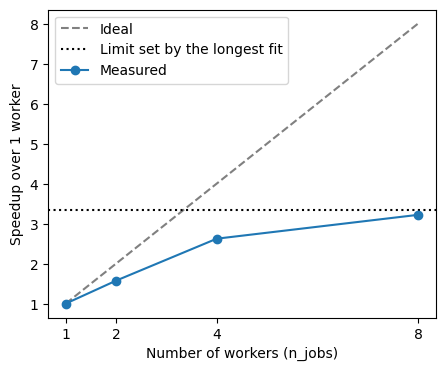

In [26]:
speedup = {k: wall_times[1] / t for k, t in wall_times.items()}

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(n_jobs_list, n_jobs_list, "--", color="grey", label="Ideal")
ax.axhline(wall_times[1] / longest_fit, linestyle=":", color="black", label="Limit set by the longest fit")
ax.plot(n_jobs_list, [speedup[k] for k in n_jobs_list], "o-", label="Measured")
ax.set_xlabel("Number of workers (n_jobs)")
ax.set_ylabel("Speedup over 1 worker")
ax.set_xticks(n_jobs_list)
ax.legend()
plt.show()

The speedup is good, but below ideal, and falls further behind as we add workers. Some reasons:

* **Load imbalance.** The fits vary in length by a factor of 100. The search cannot finish until its slowest fit has finished, however many workers we have, so the speedup can never exceed the dotted line. Near the end, most workers sit idle while one finishes a long fit.
* **Overheads**: sending data and results between processes.
* **Not all cores are equal.** Logical cores share a physical core, efficiency cores are slower, and a laptop slows its cores down when they all get hot.
* Does the computer lie about the real_cpus for hyperthreading?

## 3.4 The full search

Now we run all of the configurations, on all of the cores.

In [27]:
t0 = time.perf_counter()
results = pd.DataFrame(run_search(configs, seeds, n_jobs=n_cores)).astype({"max_depth": "Int64"})
wall_time = time.perf_counter() - t0

print("Wall-clock time: %.1f seconds" % wall_time)
print("Total compute time across all fits: %.1f seconds" % results["fit_time"].sum())
print("Number of worker processes used:", results["worker"].nunique())
results.sort_values("accuracy", ascending=False).head(8).round(3)

Wall-clock time: 4.5 seconds
Total compute time across all fits: 20.7 seconds
Number of worker processes used: 8


,n_estimators,max_depth,max_features,mean_depth,fit_time,predict_time,accuracy,worker
2,147,12,0.056,12.000,0.492,0.030,0.972,76915
1,35,12,0.104,12.000,0.137,0.006,0.972,76920
6,166,12,0.098,11.970,0.708,0.034,0.972,76912
13,79,16,0.101,13.443,0.394,0.013,0.970,76920
14,250,16,0.137,13.048,1.374,0.044,0.970,76917
24,59,16,0.173,13.169,0.386,0.010,0.969,76916
22,100,16,0.129,13.380,0.532,0.021,0.969,76912
15,214,8,0.092,8.000,0.857,0.033,0.967,76918


## 3.5 The accuracy-compute trade-off

Each point below is one configuration, plotting its validation accuracy against the time it took to fit. The three panels show the same points, coloured by each hyperparameter in turn.

The grey line is the **Pareto front**: the configurations for which no other configuration is both faster *and* more accurate. Only configurations on the front are worth considering; everything else is beaten on both counts.

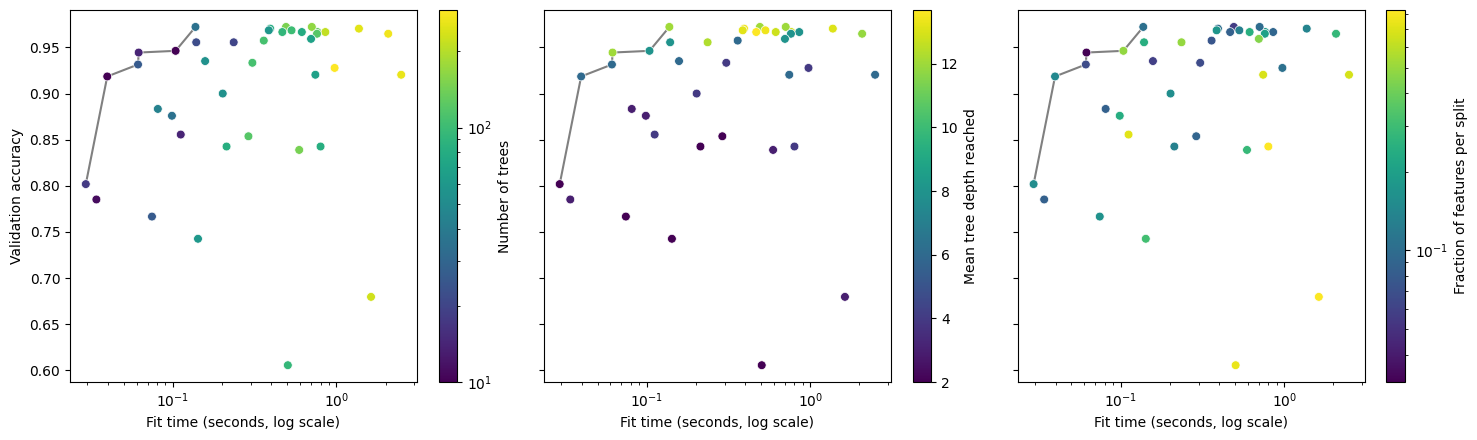

,n_estimators,max_depth,max_features,mean_depth,fit_time,predict_time,accuracy
0,18,2,0.154,2.0,0.029,0.001,0.802
9,10,6,0.144,6.0,0.040,0.001,0.919
7,26,6,0.066,6.0,0.061,0.005,0.931
33,14,12,0.031,12.0,0.062,0.004,0.944
23,10,8,0.486,8.0,0.104,0.005,0.946
1,35,12,0.104,12.0,0.137,0.006,0.972


In [28]:
by_time = results.sort_values("fit_time")
pareto = by_time[by_time["accuracy"] > by_time["accuracy"].cummax().shift(fill_value=0)]

colour_by = {"n_estimators": "Number of trees",
             "mean_depth": "Mean tree depth reached",
             "max_features": "Fraction of features per split"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (column, label) in zip(axes, colour_by.items()):
    ax.plot(pareto["fit_time"], pareto["accuracy"], "-", color="grey", zorder=1)
    points = ax.scatter(results["fit_time"], results["accuracy"], c=results[column],
                        cmap="viridis", s=40, edgecolor="white", linewidth=0.5,
                        norm="log" if column != "mean_depth" else None, zorder=2)
    fig.colorbar(points, ax=ax, label=label)
    ax.set_xscale("log")
    ax.set_xlabel("Fit time (seconds, log scale)")
axes[0].set_ylabel("Validation accuracy")
plt.tight_layout()
plt.show()

pareto[["n_estimators", "max_depth", "max_features", "mean_depth",
        "fit_time", "predict_time", "accuracy"]].round(3)

To put numbers on the costs, we can fit a simple model for how the compute time scales with each hyperparameter:

$$\log(\text{time}) = c + \beta_1 \log(\text{trees}) + \beta_2 \log(\text{depth}) + \beta_3 \log(\text{features})$$

A coefficient $\beta = 1$ means time is proportional to that hyperparameter; $\beta = 0$ means it has no effect. We fit this separately for the training time and the prediction time.

In [29]:
design = np.column_stack([np.ones(len(results)),
                          np.log(results["n_estimators"]),
                          np.log(results["mean_depth"]),
                          np.log(results["max_features"])])

cost_model = pd.DataFrame({
    target: np.linalg.lstsq(design, np.log(results[target]), rcond=None)[0][1:]
    for target in ["fit_time", "predict_time"]},
    index=["trees", "depth", "features"])
cost_model.round(2)

,fit_time,predict_time
trees,0.99,0.83
depth,0.51,0.50
features,0.49,0.02


Your exact numbers will differ, but you should find something like this:

* **Number of trees**: time is roughly proportional to it ($\beta \approx 1$), for both training and prediction. But accuracy levels off after a few tens of trees, so most of the expensive forests are wasting compute.
* **Depth**: this matters most for accuracy. Shallow trees are cheap but inaccurate, and the most accurate forests have deep trees. Time grows more slowly than depth ($\beta$ well below 1), because the deeper levels of a tree split fewer and fewer data points.
* **Features per split**: training time grows with it, but **prediction time grows much less, if at all** ($\beta$ near 0; prediction times are only milliseconds, so this estimate is noisy), because a fitted tree tests one feature per split whatever `max_features` was. Small values (scikit-learn's default is $\sqrt{64} = 8$ features, a fraction of 0.125) are as accurate as large ones, and cheaper to train.


## 3.6 An emulator of the trade-off

So far we have only *measured* configurations. We're now going to address the Portfolio question of making an "emulator". This makes sense if we had a vast amount of data and/or the Random Forest was some very expensive model.

In this frame, The RF is an expensive **simulator**: it maps hyperparameters to validation accuracy and fit time. An **emulator** is a cheap model that *predicts* what the simulator would output for hyperparameters we have not tried.

The cost model above only described fit time. Our emulator makes two predictions:

* `fit_time_model` predicts the fit time. It is the same power law as Section 3.5, but now used for prediction.
* `error_model` predicts the validation error, $1 - \text{accuracy}$. The error falls and then levels off, so a straight line will not do: we add squared terms, which allow the prediction to curve. We model the log of the error, so that predictions are always positive.

For depth we use the depth the trees actually reached (`mean_depth`), because `max_depth=None` is not a number.

In [30]:
from sklearn.linear_model import LinearRegression

def log_inputs(n_estimators, depth, max_features):
    """Emulator inputs: the logs of the three hyperparameters"""
    return np.column_stack([np.log(n_estimators), np.log(depth), np.log(max_features)])

def with_squares(inputs):
    """Add squared terms, so that a prediction can curve"""
    return np.column_stack([inputs, inputs ** 2])

inputs = log_inputs(results["n_estimators"], results["mean_depth"], results["max_features"])
fit_time_model = LinearRegression().fit(inputs, np.log(results["fit_time"]))
error_model = LinearRegression().fit(with_squares(inputs), np.log(1 - results["accuracy"]))

def emulate(n_estimators, depth, max_features):
    """Predicted validation error and fit time, without fitting any forests"""
    inputs = log_inputs(n_estimators, depth, max_features)
    return (np.exp(error_model.predict(with_squares(inputs))),
            np.exp(fit_time_model.predict(inputs)))

print("R^2 of the fit time model: %.2f" % fit_time_model.score(inputs, np.log(results["fit_time"])))
print("R^2 of the error model:    %.2f" % error_model.score(with_squares(inputs), np.log(1 - results["accuracy"])))

R^2 of the fit time model: 0.98
R^2 of the error model:    0.95


### Combining the predictions: a loss with an optimum

To choose a configuration we need a single number to minimise. We put a **price on compute**, $\lambda$: the increase in error we would accept to save one second of fit time.

$$\text{loss} = \text{error} + \lambda \times \text{fit time}$$

More trees reduce the error, but with diminishing returns, while the fit time keeps growing in proportion. So the price creates an optimum number of trees *inside* the range we searched, rather than at an edge.

Because the emulator is "cheap", we can evaluate it on a grid of 64,000 configurations in a fraction of a second, far more than we could ever fit. The grid stays within the range of the search: an emulator should not be trusted beyond the data it was trained on.

In [31]:
price = 0.01  # lambda: one percentage point of accuracy is worth one second per fit

grid = pd.DataFrame(
    np.array(np.meshgrid(np.geomspace(10, 300, 40),                         # n_estimators
                         np.geomspace(2, results["mean_depth"].max(), 40),  # depth reached
                         np.geomspace(0.03, 1, 40))                         # max_features
             ).reshape(3, -1).T,
    columns=["n_estimators", "depth", "max_features"])

grid["error"], grid["fit_time"] = emulate(grid["n_estimators"], grid["depth"], grid["max_features"])
grid["loss"] = grid["error"] + price * grid["fit_time"]
best = grid.loc[grid["loss"].idxmin()]
best.round(3)

n_estimators    48.056
depth           13.685
max_features     0.116
error            0.028
fit_time         0.277
loss             0.031
Name: 63135, dtype: float64

To see why this is the optimum, we vary one hyperparameter at a time, holding the other two at their best values. In each panel, the loss (black) is the sum of the predicted error and the price of the predicted fit time.

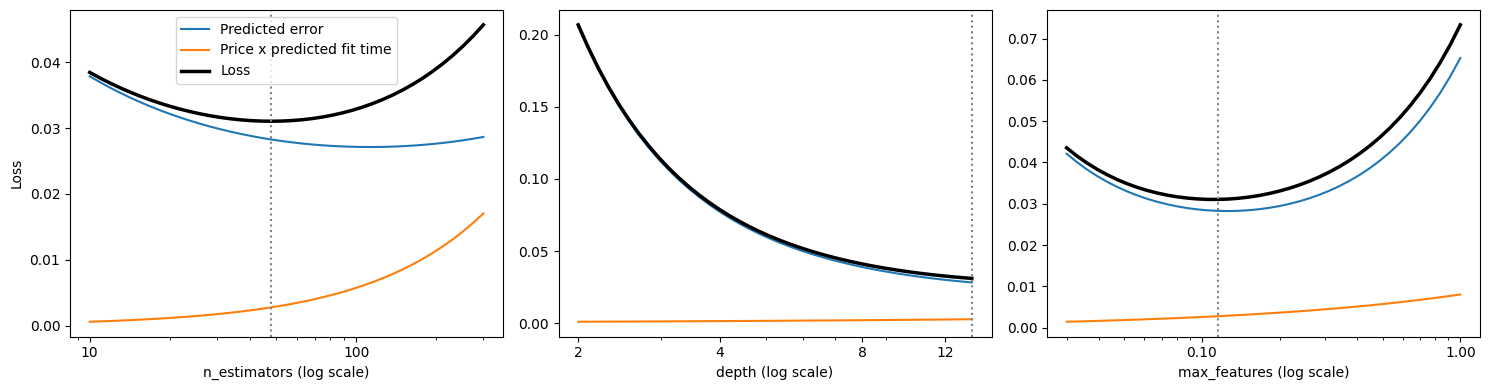

In [32]:
hyperparameters = ["n_estimators", "depth", "max_features"]

from matplotlib.ticker import ScalarFormatter, NullFormatter

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, hyperparameters):
    others = [h for h in hyperparameters if h != column]
    line = grid[(grid[others[0]] == best[others[0]]) & (grid[others[1]] == best[others[1]])]
    ax.plot(line[column], line["error"], label="Predicted error")
    ax.plot(line[column], price * line["fit_time"], label="Price x predicted fit time")
    ax.plot(line[column], line["loss"], color="black", linewidth=2.5, label="Loss")
    ax.axvline(best[column], linestyle=":", color="grey")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    if column == "depth":
        ax.set_xticks([2, 4, 8, 12])
    ax.set_xlabel(column + " (log scale)")
axes[0].set_ylabel("Loss")
axes[0].legend()
plt.tight_layout()
plt.show()

### Checking the emulator with the simulator

The emulator's choice is only a prediction. We check it by running the simulator at the chosen configuration, with a different seed on each core, so that we also see how much the result varies from fit to fit.

For comparison, we take the best configuration that the search actually ran, judged by the same loss. Its loss in the search came from a single fit, so we re-run it with the same seeds as the emulator's choice, to compare like with like.

In [33]:
chosen = {"n_estimators": int(round(best["n_estimators"])),
          "max_depth": int(round(best["depth"])),
          "max_features": float(best["max_features"])}

results["loss"] = (1 - results["accuracy"]) + price * results["fit_time"]
best_run = results.loc[results["loss"].idxmin()]
best_in_search = {"n_estimators": int(best_run["n_estimators"]),
                  "max_depth": None if pd.isna(best_run["max_depth"]) else int(best_run["max_depth"]),
                  "max_features": float(best_run["max_features"])}

def summarise(runs):
    """Mean error, fit time and loss over repeated simulator runs"""
    error, fit_time = 1 - runs["accuracy"].mean(), runs["fit_time"].mean()
    return [error, fit_time, error + price * fit_time]

check_chosen = pd.DataFrame(run_search([chosen] * n_cores, range(n_cores), n_jobs=n_cores))
check_search = pd.DataFrame(run_search([best_in_search] * n_cores, range(n_cores), n_jobs=n_cores))

print("Emulator's choice:      ", chosen)
print("Best run in the search: ", best_in_search)
pd.DataFrame({"Emulator's choice: predicted": [best["error"], best["fit_time"], best["loss"]],
              "Emulator's choice: re-run": summarise(check_chosen),
              "Best in search: in the search": [1 - best_run["accuracy"], best_run["fit_time"], best_run["loss"]],
              "Best in search: re-run": summarise(check_search)},
             index=["error", "fit time", "loss"]).round(3).T

Emulator's choice:       {'n_estimators': 48, 'max_depth': 14, 'max_features': 0.11556966357953007}
Best run in the search:  {'n_estimators': 35, 'max_depth': 12, 'max_features': 0.10413993912463357}


,error,fit time,loss
Emulator's choice: predicted,0.028,0.277,0.031
Emulator's choice: re-run,0.038,0.261,0.040
Best in search: in the search,0.028,0.137,0.029
Best in search: re-run,0.039,0.154,0.040


We've done this for exploring parallelism, but some things to note:

* **The optimum makes sense.**  The emulator's choice is usually close to scikit-learn's default ($\sqrt{64}/64 = 0.125$), which it was never told.
* **The emulator's shape is an assumption.** It gets worse with more trees which can't happen. Emulators are least reliable where there are few simulator runs, and at the edges of the range.
* **winner's curse**. The best values have noise, which makes them look better than they are when we take the maximum!
* **Uncertanity**. This emulator does not know how uncertain it is.

This is all not necessary for this problem, but could be for your own model development.

## 3.7 In practice: let scikit-learn do it

The search above is what scikit-learn's `RandomizedSearchCV` does internally, using joblib, with cross-validation instead of a single validation set. `n_jobs=-1` parallelises over all of the (configuration, fold) pairs. It also records the fit time of each configuration, so the trade-off analysis above still applies.

In [34]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=1),
    param_distributions={"n_estimators": [10, 20, 50, 100, 200],
                         "max_depth": depth_options,
                         "max_features": loguniform(0.03, 1.0)},
    n_iter=16, cv=3, n_jobs=n_cores, random_state=0)

t0 = time.perf_counter()
search.fit(X_train, y_train)
print("16 configurations x 3 folds in %.1f seconds" % (time.perf_counter() - t0))

cv_results = pd.DataFrame(search.cv_results_)
cv_results[["param_n_estimators", "param_max_depth", "param_max_features",
            "mean_fit_time", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score").head(8).round(3)

16 configurations x 3 folds in 6.3 seconds


,param_n_estimators,param_max_depth,param_max_features,mean_fit_time,mean_test_score,rank_test_score
12,100,None,0.043,0.322,0.968,1
13,200,16,0.453,1.581,0.960,2
2,200,6,0.289,1.383,0.950,3
9,100,6,0.186,0.524,0.949,4
10,20,16,0.375,0.190,0.947,5
0,10,8,0.240,0.046,0.940,6
4,10,8,0.115,0.044,0.927,7
1,20,6,0.608,0.163,0.924,8


# Additional information

What parallel approaches work?

**Safe choices**, from a notebook, on any operating system:

1. **joblib** (`Parallel` and `delayed`). It sends functions *by value* (using `cloudpickle`), so functions defined in the notebook, and even lambdas, just work. It is what scikit-learn uses for every `n_jobs` argument.
2. **The standard library, with the worker functions in a `.py` module that you import.** The workers can import the module, so the "by name" lookup succeeds. See Section 2.
3. **A library's own parallelism.** `n_jobs=-1` in scikit-learn, numpy's multithreaded linear algebra, polars, xgboost/lightgbm threads, PyTorch. Check for this first: it is free.
4. **A script run from the terminal** (`python myscript.py`), with the main code protected by `if __name__ == "__main__":`. This is the most robust option, and the right one for long jobs and for clusters.

**Things that may not work:**

* `multiprocessing.Pool` or `ProcessPoolExecutor` with functions defined in the notebook (Windows, macOS, and Linux from Python 3.14).
* Lambdas, nested functions, or functions defined inside `if __name__ == "__main__":` with the standard library, on any OS.
* `print()` inside a worker. The output may appear late, out of order, in a later cell, in the terminal running Jupyter, or not at all. **Return information from the worker instead of printing it.**
* Changing a global variable inside a worker. The main process never sees the change (Section 1.5).
* Trusting `os.cpu_count()` on a shared machine. Hosted notebooks and HPC jobs may give you fewer cores than it reports (Section 1.2).

## Other hints

* **Batching.** joblib's `batch_size` (by default `"auto"`) controls how many tasks are sent to a worker at once. Larger batches reduce overhead for many small tasks.
* **Threads instead of processes.** `Parallel(n_jobs=8, prefer="threads")` uses threads, which share memory and start instantly. This helps when tasks spend their time waiting (for downloads or disk), or in libraries such as numpy that release Python's global interpreter lock (GIL). For pure Python code, threads do not run in parallel, except in the "free-threaded" build of Python 3.14+, which is not yet the default.
* **Oversubscription.** numpy, scikit-learn and PyTorch use several threads by themselves. joblib limits these threads inside its workers automatically. Elsewhere, set the environment variable `OMP_NUM_THREADS=1` before starting Python, or use the `threadpoolctl` package.
* **Scripts.** In a script that uses `multiprocessing` (or joblib), put the main code under `if __name__ == "__main__":`. Without it, each spawned worker re-runs the script's top-level code when it starts.
* **Lambdas with the standard library.**  `multiprocess`, like joblib, can send lambdas and notebook functions.
* **Many independent runs of a script.** The shell can run these in parallel without any Python parallelism: for example `seq 16 | xargs -P 8 -I{} python run.py --seed {}`, GNU `parallel`, or a SLURM job array on a cluster.
* **Beyond one machine.** [Dask](https://www.dask.org/) and [Ray](https://www.ray.io/) run the same map and futures patterns over a cluster. joblib can use Dask as a backend, so code like Section 3 can scale without being rewritten. Or check out [Spark](https://dsbristol.github.io/dst/coursebook/11.html).
* **R.** `parallel::mclapply` uses fork, so it runs serially on Windows. The `future` and `furrr` packages provide a cross-platform alternative.